# Score your simulator against your fills

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sarptandoven/queuetruth/blob/main/examples/notebooks/04_score_simulator_vs_fills.ipynb)

The final test of a fill model is not a benchmark, it is your own trading: replay the orders you really sent
through your simulator and compare, order by order, which ones filled. `qt.score` does that and answers in the
terms a desk uses: the 2x2 table of live versus simulated outcomes, the signed fill-rate bias with a confidence
interval, a cluster-robust test of the disagreement, markouts of the fills each side got, and pass/fail gates for
CI.

Data: queuetruth's **synthetic** dataset and its synthetic live log (`own_orders/live`: 200 order lives of the
synthetic tape in the canonical live-log format, standing in for "your orders"). Nothing here is a real venue or a
real account; the workflow is the same with a log built by `queuetruth import-live` from your venue or broker.

Three simulators are scored:

1. **A naive simulator written here in 20 lines of pandas**: a resting order fills in full as soon as a trade
   prints at or through its price. Many backtesters work this way.
2. **A stricter variant** that needs a trade strictly through the price.
3. **A zoo model**, hftbacktest's `power3` queue model, and the **exact** replay arm for reference.

In [1]:
# Setup: on Colab (or anywhere queuetruth is missing) this installs it from PyPI; elsewhere it does nothing.
import importlib
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("queuetruth") is None:
    try:
        from IPython import get_ipython

        shell = get_ipython()
    except ImportError:
        shell = None
    if shell is not None:  # %pip lets Colab offer a restart when an already-imported package was upgraded
        shell.run_line_magic("pip", "install -q queuetruth pandas matplotlib")
    else:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "queuetruth", "pandas", "matplotlib"])
    importlib.invalidate_caches()
if importlib.util.find_spec("queuetruth") is None or importlib.util.find_spec("queuetruth.frames") is None:
    raise RuntimeError(
        "this notebook needs queuetruth.frames (first released after queuetruth 0.1.1): pip install -U queuetruth"
    )

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq

import queuetruth as qt
from queuetruth import frames

pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 70)
plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (7.5, 3.4)})

WORK = Path("qt-notebooks") / "04_score"
WORK.mkdir(parents=True, exist_ok=True)
DATA = WORK / "synth"
if not (DATA / "manifest.json").exists():
    qt.fixtures_synth(str(DATA))
LIVE = DATA / "own_orders" / "live"
print("queuetruth", qt.__version__, "| synthetic data and synthetic live log")

queuetruth 0.1.1 | synthetic data and synthetic live log


## 1. The live log

A canonical live log is two Parquet tables: `orders` (one row per order) and `events` (submit, ack, fills, cancel,
done, with exchange and local timestamps). `qt.validate_live` checks it before anything is scored.

In [3]:
print("validation warnings:", qt.validate_live(str(LIVE)) or "none")
orders = frames.read(LIVE / "orders.parquet", expect="qt.live_orders")
events = frames.read(LIVE / "events.parquet", expect="qt.live_events")
print(len(orders), "orders,", len(events), "events")
events["event_type"].value_counts()

validation warnings: none
200 orders, 879 events


event_type
submit_sent    200
ack            200
done           200
fill           151
cancel_sent     64
cancel_ack      64
Name: count, dtype: int64

## 2. A naive simulator

The simulator sees the same tape: the trades of the exact replay (`qt.replay`, read with `frames.load_run`). For
each order it takes the exchange ack as the time the order rests and the cancel ack (if any) as the time it stops,
and fills the whole order at the first trade at or through its price in between. It writes its fills as a
simulator log: `orders.parquet` (the order keys it saw) and `events.parquet` (one `fill` row per fill).

In [4]:
qt.replay({"dataset": {"path": str(DATA)}, "out": str(WORK / "tape")})
trades = frames.load_run(WORK / "tape")["trades"]

ack = events[events["event_type"] == "ack"].groupby("order_key")["ts_exchange"].min()
cancel = events[events["event_type"] == "cancel_ack"].groupby("order_key")["ts_exchange"].min()
book = orders.set_index("order_key").join(ack.rename("ts_rest")).join(cancel.rename("ts_stop"))


def naive_sim(book, trades, strict):
    """Fill each order in full at the first trade at (or, if `strict`, through) its price while it rests."""
    fills = []
    for key, o in book.iterrows():
        t = trades[(trades["instrument_id"] == o["instrument_id"]) & (trades["ts_event"] > o["ts_rest"])]
        if pd.notna(o["ts_stop"]):
            t = t[t["ts_event"] < o["ts_stop"]]
        buy = o["side"] == "buy"
        if strict:
            t = t[t["price"] < o["limit_px"]] if buy else t[t["price"] > o["limit_px"]]
        else:
            t = t[t["price"] <= o["limit_px"]] if buy else t[t["price"] >= o["limit_px"]]
        if len(t):
            fills.append(
                {
                    "order_key": key,
                    "event_type": "fill",
                    "qty": int(o["orig_qty"]),
                    "px": int(o["limit_px"]),
                    "fill_id": f"{key}-sim",
                    "ts_exchange": t["ts_event"].iloc[0],
                    "source": "sim:naive",
                }
            )
    return pd.DataFrame(fills)


def write_sim_log(fills, out):
    out.mkdir(parents=True, exist_ok=True)
    pq.write_table(pa.table({"order_key": list(book.index)}), out / "orders.parquet")
    pq.write_table(pa.Table.from_pandas(fills, preserve_index=False), out / "events.parquet")
    return out


touch_log = write_sim_log(naive_sim(book, trades, strict=False), WORK / "sim-touch")
through_log = write_sim_log(naive_sim(book, trades, strict=True), WORK / "sim-through")
for log in (touch_log, through_log):
    print(log.name, len(pq.read_table(log / "events.parquet")), "simulated fills of", len(book), "orders")

sim-touch 153 simulated fills of 200 orders
sim-through 135 simulated fills of 200 orders


## 3. Score every simulator against the live fills

`sim` is `{"kind": "external", "log": ...}` for your own simulator's log, `{"kind": "zoo", "model": ...}` for a
zoo model and `{"kind": "exact"}` for the exact replay (which removes your own orders from the tape first, so the
replayed order does not queue behind its own twin). Outcomes are compared within 60 s of entry.

In [5]:
def score(name, sim, **extra):
    return qt.api.score(
        {
            "live": {"path": str(LIVE)},
            "sim": sim,
            "dataset": {"path": str(DATA)},
            "out": str(WORK / name),
            "bootstrap": {"b": 500},
            "perm_b": 500,
            **extra,
        }
    )


cards = {
    "naive touch": score("score-touch", {"kind": "external", "log": {"path": str(touch_log)}}),
    "naive through": score("score-through", {"kind": "external", "log": {"path": str(through_log)}}),
    "hbt power3 n=2": score("score-power3", {"kind": "zoo", "model": "hbt_power3[n=2]"}),
    "exact replay": score("score-exact", {"kind": "exact"}),
}
board = frames.scorecards(cards)
cols = [
    "n_orders",
    "n_matched",
    "both",
    "neither",
    "live_only",
    "sim_only",
    "fill_rate_bias",
    "ci_lo",
    "ci_hi",
    "direction",
]
cols += ["discordance_p"]
board.set_index("label")[cols].round(4)

,n_orders,n_matched,both,neither,live_only,sim_only,fill_rate_bias,ci_lo,ci_hi,direction,discordance_p
label,,,,,,,,,,,
naive touch,200,200,112,70,0,18,0.0900,0.0551,0.1251,sim_overfills,0.0001
naive through,200,200,76,88,36,0,-0.1800,-0.2242,-0.1414,sim_underfills,0.0000
hbt power3 n=2,200,184,93,88,3,0,-0.0163,-0.0350,0.0000,no_significant_bias,0.0862
exact replay,200,200,112,88,0,0,0.0000,0.0000,0.0000,no_significant_bias,1.0000


`sim_only` orders are fills your simulator grants that the market did not; `live_only` are fills it misses.
`fill_rate_bias` is `(sim_only - live_only) / matched`, and `discordance_p` is the primary, cluster-robust test of
whether the two kinds of disagreement are balanced (orders close in time are not independent, so the plain
McNemar p-value is reported only as a secondary statistic).

The hftbacktest arm scores fewer orders (`n_matched`) than the others: faithful hftbacktest aborts at its issue
#312 on some orders, and an order whose simulated pair aborted inside the scoring window has no simulator outcome,
so it is left out of that scorecard rather than counted as unfilled. Its bias is therefore measured on a slightly
different set of orders. Each scorecard's verdict says what it found in one sentence:

In [6]:
for label, s in cards.items():
    print(f"{label:15s} {s.verdict.headline}")

naive touch     sim overfills live by 9.0 pp fill rate within 60 s (95% CI [+5.5, +12.5]); cluster-robust p = 7.73e-05 (26 clusters); plain McNemar p = 7.63e-06 (assumes independent orders); 200 orders; no gates configured
naive through   sim underfills live by 18.0 pp fill rate within 60 s (95% CI [-22.4, -14.1]); cluster-robust p = 1.17e-08 (26 clusters); plain McNemar p = 2.91e-11 (assumes independent orders); 200 orders; no gates configured
hbt power3 n=2  no significant fill-rate difference within 60 s: -1.6 pp (95% CI [-3.5, +0.0]); not shown equivalent within ±2 pp (TOST p = 0.316); cluster-robust p = 0.0862 (26 clusters); plain McNemar p = 0.25 (assumes independent orders); 184 orders; no gates configured
exact replay    no significant fill-rate difference within 60 s: +0.0 pp (95% CI [+0.0, +0.0]); equivalent within ±2 pp (TOST p = 0); cluster-robust p = 1 (26 clusters); plain McNemar p = 1 (assumes independent orders); 200 orders; no gates configured


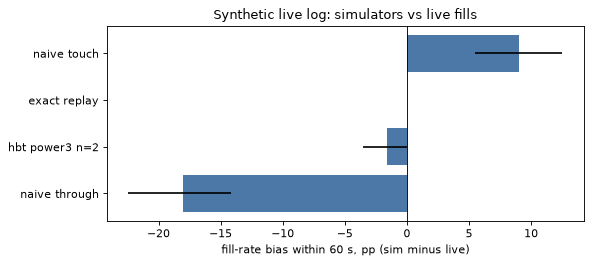

In [7]:
fig, ax = plt.subplots()
order = board.sort_values("fill_rate_bias")
err = [100 * (order["fill_rate_bias"] - order["ci_lo"]), 100 * (order["ci_hi"] - order["fill_rate_bias"])]
ax.barh(order["label"], 100 * order["fill_rate_bias"], xerr=err, color="#4c78a8")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("fill-rate bias within 60 s, pp (sim minus live)")
ax.set_title("Synthetic live log: simulators vs live fills")
fig.tight_layout()

## 4. Which orders disagree, and were those fills any good?

`score_orders` has one row per order with its class (`both`, `neither`, `live_only`, `sim_only`), the queue ahead
at entry and the liquidity bucket. Wrongly granted fills cluster where the queue ahead was deep.

In [8]:
so = frames.load_run(WORK / "score-touch")["score_orders"]
so.groupby("class", observed=True)["queue_ahead_at_entry"].describe()[["count", "mean", "50%", "max"]].round(1)

,count,mean,50%,max
class,,,,
both,112.0,13.2,7.0,69.0
neither,70.0,13.9,11.0,59.0
sim_only,18.0,24.8,16.0,78.0


Markouts show whether the extra fills were the kind a strategy wants. A markout is the mid price at a horizon
after the fill minus the fill price, in ticks, signed so that positive is in the order's favour. Below: the mean
markout of all simulated fills versus all live fills, then the simulator's wrongly granted (`sim_only`) fills
against the fills it missed (`live_only`).

In [9]:
mk = frames.records(cards["naive touch"], "markouts")
mk = mk[mk["horizon_ns"].isin([10**8, 10**9, 10**10, 6 * 10**10])]
print(mk.pivot(index="horizon_ns", columns="arm", values="mean_ticks").round(3))
disc = frames.records(cards["naive touch"], "sim_only_vs_live_only_markout")
disc[disc["horizon_ns"].isin([10**8, 10**9, 10**10, 6 * 10**10])].round(3).reset_index(drop=True)

arm           live    sim
horizon_ns               
100000000    0.320  0.512
1000000000   0.320  0.519
10000000000  0.475  0.592
60000000000  0.475  0.581


,horizon_ns,sim_only_mean,live_only_mean,diff,ci_lo,ci_hi
0,100000000,0.861,None,None,None,None
1,1000000000,0.972,None,None,None,None
2,10000000000,1.083,None,None,None,None
3,60000000000,1.028,None,None,None,None


On this synthetic tape the fills the naive simulator wrongly grants mark out at about +1 tick: profit the backtest
books on orders the live account never had filled. The simulated fills as a whole also mark out better than the
live ones, so the naive simulator overstates both how often the strategy fills and what each fill earns. The
scorecard measures the sign rather than assuming it; on your data the wrongly granted fills may just as well be
the adverse ones.

## 5. Gate it in CI

`gates` turn the scorecard into a pass/fail check: here, fail when the absolute fill-rate bias is above 2
percentage points. On the command line a failed gate exits with code 1 (`queuetruth score ... --fail-abs-bias 0.02`),
so a simulator change that makes fills more optimistic breaks the build.

In [10]:
gated = score(
    "score-touch-gated",
    {"kind": "external", "log": {"path": str(touch_log)}},
    gates={"max_abs_fill_rate_bias": 0.02},
)
print("gates passed:", gated.verdict.gates_passed, "| failed:", gated.verdict.failed_gates)

gates passed: False | failed: ['max_abs_fill_rate_bias']


## With your own data

1. Build the live log from your venue or broker export: `queuetruth import-live --format ... --out live/` (the
   how-to *Import fills from my venue or broker*).
2. Run your simulator on the same orders and write its fills as a simulator log (as `write_sim_log` above does).
3. `qt.score` (or `queuetruth score --live live/ --sim-log sim/ --data my-ds`), then `frames.scorecards` and
   `frames.load_run(...)["score_orders"]` to dig in.

On an L2-only venue there is no exact arm, but the scorecard against your fills still works;
[03](03_calibrate_and_export.ipynb) shows how to calibrate the simulator once you know it is off.